**Importing Libraries**

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

**Load Data and Explore**

In [33]:
df = pd.read_csv("/content/diabetes.csv")
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [34]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Dataset Shape: (768, 9)

Missing Values per Column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


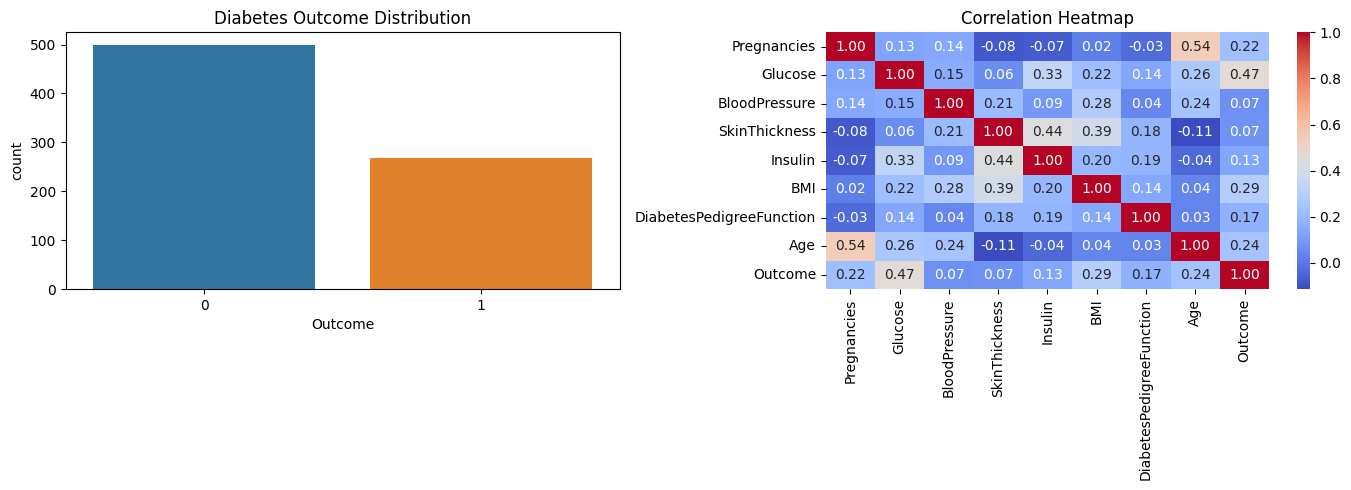

In [35]:
print(f"Dataset Shape: {df.shape}\n")
print("Missing Values per Column:")
print(df.isnull().sum())

# Plot Outcome Distribution and Correlation Heatmap side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x="Outcome", data=df, hue="Outcome", legend=False, ax=axes[0])
axes[0].set_title("Diabetes Outcome Distribution")

sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1])
axes[1].set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()

**Data Preprocessing**

In [42]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Data Shape: {X_train_scaled.shape}")
print(f"Testing Data Shape: {X_test_scaled.shape}")

Training Data Shape: (652, 8)
Testing Data Shape: (116, 8)


**Defining Models and Hyperparameter Tunning**

In [43]:
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {"C": [0.01, 0.1, 1, 10], "solver": ["liblinear", "lbfgs"]}
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {"max_depth": [3, 5, 8, None], "min_samples_split": [2, 5, 10]}
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {"n_estimators": [100, 200], "max_depth": [5, 10, None], "min_samples_split": [2, 5]}
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"n_neighbors": [3, 5, 7, 11], "weights": ["uniform", "distance"]}
    ),
    "SVM": (
        SVC(probability=True),
        {"C": [0.1, 1, 10], "kernel": ["linear", "rbf"]}
    )
}

tuned_models = {}
print("\n--- Starting Hyperparameter Tuning ---")

for name, (model, param_grid) in models.items():
    print(f"Tuning {name}...")
    grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring="accuracy", n_jobs=-1)
    grid_search.fit(X_train_scaled, y_train)

    tuned_models[name] = grid_search.best_estimator_
    print(f"  Best Acc: {grid_search.best_score_ * 100:.2f}% | Params: {grid_search.best_params_}")


--- Starting Hyperparameter Tuning ---
Tuning Logistic Regression...
  Best Acc: 78.37% | Params: {'C': 0.1, 'solver': 'liblinear'}
Tuning Decision Tree...
  Best Acc: 74.23% | Params: {'max_depth': 3, 'min_samples_split': 2}
Tuning Random Forest...
  Best Acc: 76.53% | Params: {'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 200}
Tuning KNN...
  Best Acc: 74.38% | Params: {'n_neighbors': 7, 'weights': 'uniform'}
Tuning SVM...
  Best Acc: 77.44% | Params: {'C': 0.1, 'kernel': 'linear'}


**Evaluation and Best Model Selection**


--- Final Test Accuracy (Ranked) ---
              Model  Accuracy (%)
                KNN     76.724138
Logistic Regression     74.137931
      Random Forest     74.137931
                SVM     74.137931
      Decision Tree     69.827586


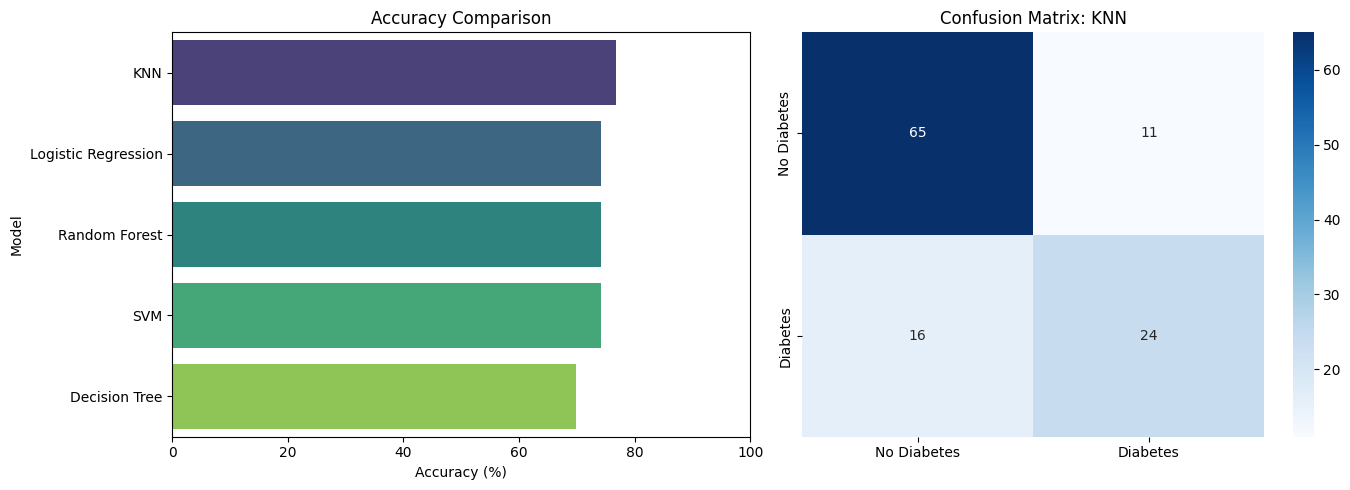


--- Classification Report: KNN ---
              precision    recall  f1-score   support

           0       0.80      0.86      0.83        76
           1       0.69      0.60      0.64        40

    accuracy                           0.77       116
   macro avg       0.74      0.73      0.73       116
weighted avg       0.76      0.77      0.76       116



In [44]:
results = []

for name, model in tuned_models.items():
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    results.append({"Model": name, "Accuracy (%)": acc * 100})

results_df = pd.DataFrame(results).sort_values(by="Accuracy (%)", ascending=False).reset_index(drop=True)

print("\n--- Final Test Accuracy (Ranked) ---")
print(results_df.to_string(index=False))

# Automatically select the best model
best_model_name = results_df.iloc[0]["Model"]
best_model = tuned_models[best_model_name]
best_accuracy = results_df.iloc[0]["Accuracy (%)"]

# Visualizing Final Results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Barplot
sns.barplot(data=results_df, x="Accuracy (%)", y="Model", hue="Model", legend=False, palette="viridis", ax=axes[0])
axes[0].set_title("Accuracy Comparison")
axes[0].set_xlim(0, 100)

# Confusion Matrix of Best Model
cm = confusion_matrix(y_test, best_model.predict(X_test_scaled))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No Diabetes", "Diabetes"], yticklabels=["No Diabetes", "Diabetes"], ax=axes[1])
axes[1].set_title(f"Confusion Matrix: {best_model_name}")

plt.tight_layout()
plt.show()

print(f"\n--- Classification Report: {best_model_name} ---")
print(classification_report(y_test, best_model.predict(X_test_scaled)))

**Prediction on new data**

In [45]:
new_patient = np.array([[2, 120, 70, 30, 100, 32.5, 0.5, 35]])

# Scale the new data using the previously fitted scaler
new_patient_scaled = scaler.transform(new_patient)

# Predict
prediction = best_model.predict(new_patient_scaled)[0]

print("\n--- New Patient Prediction ---")
print(f"Selected Model: {best_model_name}")
print(f"Prediction: {'Diabetes' if prediction == 1 else 'No Diabetes'}")

if hasattr(best_model, "predict_proba"):
    probability = best_model.predict_proba(new_patient_scaled)[0]
    print(f"Probability of No Diabetes: {probability[0] * 100:.2f}%")
    print(f"Probability of Diabetes: {probability[1] * 100:.2f}%")


--- New Patient Prediction ---
Selected Model: KNN
Prediction: No Diabetes
Probability of No Diabetes: 57.14%
Probability of Diabetes: 42.86%


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
